### Задание 2.1. Кластеризация вузов

In [3]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
import plotly.express as px


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_excel('result2022.xlsx')

In [6]:
df.head()

,"Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ","Средний балл ЕГЭ студентов университета, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы Российской Федерации, за исключением лиц, поступивших с учетом особых прав и в рамках квоты целевого приема","Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета с оплатой стоимости затрат на обучение физическими и юридическими лицами","Усредненный по реализуемым направлениям (специальностям) минимальный балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме на программы бакалавриата и специалитета","Численность студентов, победителей и призеров заключительного этапа всероссийской олимпиады школьников, членов сборных команд Российской Федерации, участвовавших в международных олимпиадах по общеобразовательным предметам по специальностям и (или) направлениям подготовки, соответствующим профилю всероссийской олимпиады школьников или международной олимпиады, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета без вступительных испытаний","Численность студентов, победителей и призеров олимпиад школьников, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета по специальностям и (или) направлениям подготовки, соответствующим профилю олимпиады школьников, без вступительных испытаний","Численность студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета","Удельный вес численности студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета в общей численности студентов, принятых на первый курс по программам бакалавриата и специалитета на очную форму обучения","Удельный вес численности студентов (приведенного контингента), обучающихся по программам магистратуры, в общей численности приведенного контингента обучающихся по образовательным программам бакалавриата, специалитета и магистратуры","Удельный вес численности обучающихся (приведенного контингента), по программам магистратуры, подготовки научно-педагогических кадров в аспирантуре (адъюнктуре), ординатуры, ассистентуры-стажировки в общей численности приведенного контингента обучающихся по основным образовательным программам высшего образования",...,Доля доходов вуза от образовательной деятельности в общих доходах вуза,Доля доходов вуза от научных исследований и разработок в общих доходах вуза,Доля внебюджетных средств в доходах от образовательной деятельности,Доля внебюджетных средств в доходах от научных исследований и разработок,VUZ,Region,Type,Site,ID,year
0,0.00,0.00,61.28,48.28,0,0,0,0.0,8.34,8.34,...,80.76,4.42,100.00,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.vepi.ru,110170,2022
1,51.69,51.69,51.48,39.26,0,0,0,0.0,0.00,0.00,...,66.01,11.19,34.13,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.iict.ru,1996,2022
2,0.00,0.00,0.00,0.00,0,0,0,0.0,0.00,0.00,...,97.58,0.00,100.00,0.00,Автономная некоммерческая образовательная орга...,Курская область,Частные образовательные организации,http://rfei.ru/,2071,2022
3,0.00,0.00,55.70,55.70,0,0,0,0.0,0.00,0.00,...,68.66,1.53,100.00,100.00,Автономная некоммерческая образовательная орга...,Московская область,Частные образовательные организации,https://www.pssi-k.ru/,666667486,2022
4,0.00,0.00,0.00,0.00,0,0,0,0.0,100.00,100.00,...,9.09,85.08,9.77,12.17,Автономная некоммерческая образовательная орга...,г.Москва,Частные образовательные организации,www.skoltech.ru,113493,2022


In [7]:
df.shape

(681, 133)

In [8]:
df.dtypes.head(15)

Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ                                                                                                                                                                                                                                                                                                        float64
Средний балл ЕГЭ студентов университета, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы Российской Федерации, за исключением лиц, поступивших с учетом особых прав и в рамках квоты целевого приема                                                                                                                                                                                  float64
Средний балл ЕГЭ сту

#### Создаём словарь для переименования очень длинных русских названий столбцов в короткие удобные имена

In [9]:
col_rename = {
    "Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы РФ": "ege_avg_budget_full_time",
    "Средний балл ЕГЭ студентов университета, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета за счет средств соответствующих бюджетов бюджетной системы Российской Федерации, за исключением лиц, поступивших с учетом особых прав и в рамках квоты целевого приема": "ege_avg_budget_full_time_no_special_rights_no_target_quota",
    "Средний балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме по программам бакалавриата и специалитета с оплатой стоимости затрат на обучение физическими и юридическими лицами": "ege_avg_paid_full_time",
    "Усредненный по реализуемым направлениям (специальностям) минимальный балл ЕГЭ студентов, принятых по результатам ЕГЭ на обучение по очной форме на программы бакалавриата и специалитета": "ege_min_avg_full_time",
    "Численность студентов, победителей и призеров заключительного этапа всероссийской олимпиады школьников, членов сборных команд Российской Федерации, участвовавших в международных олимпиадах по общеобразовательным предметам по специальностям и (или) направлениям подготовки, соответствующим профилю всероссийской олимпиады школьников или международной олимпиады, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета без вступительных испытаний": "olympiad_final_winners_admitted_no_exams",
    "Численность студентов, победителей и призеров олимпиад школьников, принятых на очную форму обучения на первый курс по программам бакалавриата и специалитета по специальностям и (или) направлениям подготовки, соответствующим профилю олимпиады школьников, без вступительных испытаний": "school_olympiad_winners_admitted_no_exams",
    "Численность студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета": "target_admission_count_full_time",
    "Удельный вес численности студентов, принятых по результатам целевого приема на первый курс на очную форму обучения по программам бакалавриата и специалитета в общей численности студентов, принятых на первый курс по программам бакалавриата и специалитета на очную форму обучения": "target_admission_share_full_time",
    "Удельный вес численности студентов (приведенного контингента), обучающихся по программам магистратуры, в общей численности приведенного контингента обучающихся по образовательным программам бакалавриата, специалитета и магистратуры": "masters_share_in_total_contingent",
    "Удельный вес численности обучающихся (приведенного контингента), по программам магистратуры, подготовки научно-педагогических кадров в аспирантуре (адъюнктуре), ординатуры, ассистентуры-стажировки в общей численности приведенного контингента обучающихся по основным образовательным программам высшего образования": "postgrad_and_residency_share_in_total_contingent",
    "Удельный вес численности студентов, имеющих диплом бакалавра, специалиста или магистра других организаций, принятых на первый курс на обучение по программам магистратуры образовательной организации, в общей численности студентов, принятых на первый курс по программам магистратуры на очную форму обучения": "masters_admitted_from_other_orgs_share_full_time",
    "Удельный вес численности обучающихся по программам магистратуры, подготовки научно-педагогических кадров в аспирантуре (адъюнктуре), ординатуры, ассистентуры-стажировки, имеющих диплом бакалавра, диплом специалиста или диплом магистра других организаций в общей численности обучающихся по программам магистратуры, подготовки научно-педагогических кадров в аспирантуре (адъюнктуре), ординатуры, ассистентуры-стажировки": "postgrad_from_other_orgs_share",
    "Численность аспирантов (адъюнктов), ординаторов, ассистентов-стажеров образовательной организации в расчете на 100 студентов (приведенного контингента)": "postgrad_per_100_students",
    "Удельный вес численности слушателей из сторонних организаций в общей численности слушателей, прошедших обучение в образовательной организации по программам повышения квалификации или профессиональной переподготовки": "dpo_external_listeners_share",
    "Удельный вес численности студентов, обучающихся по направлениям подготовки бакалавриата, специалитета, и магистратуры по областям знаний «Инженерное дело, технологии и технические науки», «Здравоохранение и медицинские науки», «Образование и педагогические науки», с которыми заключены договоры о целевом обучении, в общей численности студентов, обучающихся по указанным областям знаний": "target_contract_share_priority_fields",

    "Количество цитирований публикаций, изданных за последние 5 лет, индексируемых в информационно-аналитической системе научного цитирования Web of Science Core Collection в расчете на 100 НПР[н]": "citations_wos_5y_per_100_faculty",
    "Количество цитирований публикаций, изданных за последние 5 лет, индексируемых в информационно-аналитической системе научного цитирования Scopus в расчете на 100 НПР[н]": "citations_scopus_5y_per_100_faculty",
    "Количество цитирований публикаций, изданных за последние 5 лет, индексируемых в Российском индексе научного цитирования (далее – РИНЦ) в расчете на 100 НПР[н]": "citations_rinc_5y_per_100_faculty",
    "Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования Web of Science Core Collection, в расчете на 100 НПР[н]": "publications_wos_per_100_faculty",
    "Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования Scopus, в расчете на 100 НПР[н]": "publications_scopus_per_100_faculty",
    "Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования РИНЦ, в расчете на 100 НПР[н]": "publications_rinc_per_100_faculty",
    "Общий объем научно-исследовательских и опытно-конструкторских работ (далее – НИОКР)": "rnd_total_volume",
    "Удельный вес доходов от НИОКР в общих доходах образовательной организации": "rnd_income_share_total",
    "Удельный вес НИОКР, выполненных собственными силами (без привлечения соисполнителей), в общих доходах образовательной организации от НИОКР": "rnd_own_work_share_in_rnd_income",
    "Доходы от НИОКР (за исключением средств бюджетов бюджетной системы Российской Федерации, государственных фондов поддержки науки) в расчете на одного НПР[н]": "rnd_income_per_faculty_excl_budget",
    "Количество лицензионных соглашений": "license_agreements_count",
    "Удельный вес средств, полученных образовательной организацией от использования результатов интеллектуальной деятельности, в общих доходах образовательной организации": "rid_income_share_total",
    "Удельный вес численности НПР без ученой степени – до 30 лет, кандидатов наук – до 35 лет, докторов наук – до 40 лет, в общей численности НПР[н]": "young_faculty_share",
    "Удельный вес научно-педагогических работников, защитивших кандидатские и докторские диссертации за отчетный период в общей численности НПР": "defended_theses_share",
    "Количество научных журналов, в том числе электронных, издаваемых образовательной организацией": "journals_count",
    "Количество полученных грантов за отчетный год в расчете на 100 НПР[н]": "grants_per_100_faculty",

    "Удельный вес численности иностранных студентов (кроме стран Содружества Независимых Государств (далее – СНГ)), обучающихся программам бакалавриата, специалитета, магистратуры, в общей численности студентов (приведенный контингент)": "foreign_students_non_cis_share",
    "Удельный вес численности иностранных студентов из СНГ, обучающихся по программам бакалавриата, специалитета, магистратуры, в общей численности студентов (приведенный контингент)": "foreign_students_cis_share",
    "Удельный вес численности иностранных студентов, завершивших освоение образовательных программ бакалавриата, специалитета, магистратуры, в общей численности студентов (приведенный контингент)": "foreign_graduates_share",
    "Удельный вес численности иностранных студентов (кроме стран СНГ), завершивших освоение образовательных программ бакалавриата, программ специалитета, программ магистратуры, в общей численности студентов (приведенный контингент)": "foreign_graduates_non_cis_share",
    "Удельный вес численности иностранных студентов из стран СНГ, завершивших освоение образовательных программ бакалавриата, программ специалитета, программ магистратуры, в общей численности студентов (приведенный контингент)": "foreign_graduates_cis_share",
    "Удельный вес численности студентов, обучающихся по очной форме обучения по образовательным программам бакалавриата, программам специалитета, программам магистратуры, прошедших обучение за рубежом не менее семестра (триместра), в общей численности студентов, обучающихся по очной форме обучения": "outbound_mobility_semester_share",
    "Численность студентов иностранных образовательных организаций, прошедших обучение в образовательной организации по образовательным по очной форме обучения по образовательным программам бакалавриата, программам специалитета, программам магистратуры, не менее семестра (триместра) в расчете на 100 студентов, обучающихся по очной форме обучения": "inbound_mobility_per_100_students",
    "Удельный вес численности иностранных граждан из числа НПР в общей численности НПР": "foreign_faculty_share",
    "Численность зарубежных ведущих профессоров, преподавателей и исследователей, работающих (работавших) в образовательной организации не менее 1 семестра": "visiting_professors_count",
    "Удельный вес численности иностранных граждан (кроме стран СНГ) из числа аспирантов (адъюнктов), ординаторов, ассистентов-стажеров образовательной организации в общей численности аспирантов (адъюнктов), ординаторов, ассистентов-стажеров": "foreign_postgrad_non_cis_share",
    "Удельный вес численности иностранных граждан из стран СНГ из числа аспирантов (адъюнктов), ординаторов, ассистентов-стажеров образовательной организации в общей численности аспирантов (адъюнктов), ординаторов, ассистентов-стажеров": "foreign_postgrad_cis_share",
    "Объем средств, полученных образовательной организацией от выполнения НИОКР от иностранных граждан и иностранных юридических лиц": "rnd_funds_from_foreign_entities",
    "Объем средств от образовательной деятельности, полученных образовательной организацией от иностранных граждан и иностранных юридических лиц": "edu_funds_from_foreign_entities",

    "Доходы образовательной организации из средств от приносящей доход деятельности в расчете на одного НПР": "income_nonbudget_per_faculty",
    "Доля доходов из средств от приносящей доход деятельности в доходах по всем видам финансового обеспечения (деятельности) образовательной организации": "income_nonbudget_share_total",
    "Отношение средней заработной платы НПР в образовательной организации (из всех источников) к средней заработной плате по экономике региона": "faculty_salary_to_region_avg_ratio",
    "Доходы образовательной организации из всех источников в расчете на численность студентов (приведенный контингент)": "income_per_student",
    "Общая площадь учебно-лабораторных помещений в расчете на одного студента (приведенного контингента),в том числе:": "teaching_lab_area_per_student_total",
    "имеющихся на праве собственности": "teaching_lab_area_owned",
    "закрепленных на праве оперативного управления": "teaching_lab_area_operational",
    "предоставленных в безвозмездное пользование": "teaching_lab_area_free_use",
    "предоставленных в аренду": "teaching_lab_area_rented",
    "Количество персональных компьютеров в расчете на одного студента (приведенного контингента)": "pcs_per_student",
    "Удельный вес стоимости машин и оборудования (не старше 5 лет) в общей стоимости машин и оборудования": "equipment_under_5y_value_share",
    "Количество экземпляров печатных учебных изданий (включая учебники и учебные пособия) из общего количества единиц хранения библиотечного фонда, состоящих на учете, в расчете на одного студента (приведенного контингента)": "printed_textbooks_per_student",
    "Удельный вес НПР, имеющих ученую степень кандидата наук, в общей численности НПР": "faculty_phd_share",
    "Удельный вес НПР имеющих ученую степень доктора наук, в общей численности НПР": "faculty_dsc_share",
    "Удельный вес НПР, имеющих ученую степень кандидата и доктора наук, в общей численности НПР образовательной организации (без совместителей и работающих по договорам гражданско-правового характера)": "faculty_phd_dsc_share",
    "Число НПР, имеющих ученую степень кандидата и доктора наук, в расчете на 100 студентов": "faculty_phd_dsc_per_100_students",
    "Доля штатных работников ППС в общей численности ППС": "faculty_staff_share",

    "2": "section_2",
    "Образовательная деятельность": "section_education",
    "Общая численность студентов, обучающихся по программам бакалавриата, специалитета, магистратуры": "students_total",
    "в том числе:по очной форме обучения": "students_full_time",
    "по очно-заочной (вечерней) форме обучения": "students_part_time_evening",
    "по заочной форме обучения": "students_correspondence",
    "Средний балл ЕГЭ студентов, принятых на обучение по программам бакалавриата и специалитета, по всем формам обучения": "ege_avg_all_forms",
    "Доля обучающихся по программам бакалавриата, специалитета, магистратуры в очной форме": "share_full_time",
    "Доля обучающихся по программам бакалавриата в общей численности обучающихся по программам бакалавриата, специалитета, магистратуры": "share_bachelor_in_total",
    "Доля обучающихся по программам магистратуры в общей численности обучающихся по программам бакалавриата, специалитета, магистратуры": "share_master_in_total",
    "Общая численность слушателей программ дополнительного профессионального образования": "dpo_listeners_total",
    "Общая численность обучающихся по программам среднего профессионального образования": "spo_students_total",
    "Число предприятий, с которыми заключены договоры на подготовку специалистов": "partner_enterprises_count",
    "Число предприятий, являющихся базами практики, с которыми оформлены договорные отношения": "practice_bases_count",

    "Научная деятельность": "section_research",
    "Общий объем средств, поступивших (за отчетный год) от выполнения НИОКР, выполненных собственными силами": "rnd_funds_own_total",
    "Общий объем средств, поступивших (за отчетный год) от выполнения работ, услуг, связанных с научными, научно-техническими, творческими услугами и разработками, выполненных собственными силами": "research_services_funds_own_total",
    "Общее количество публикаций организации в расчете на 100 НПР": "publications_total_per_100_faculty",
    "Количество бизнес-инкубаторов": "incubators_count",
    "Количество технопарков": "technoparks_count",
    "Количество центров коллективного пользования научным оборудованием": "shared_equipment_centers_count",
    "Количество малых предприятий": "small_enterprises_count",
    "Общая численность аспирантов (адъюнктов), интернов, ординаторов, ассистентов-стажеров": "postgrads_total",
    "Доля аспирантов (адъюнктов), интернов, ординаторов, ассистентов-стажеров, обучающихся в очной форме": "postgrads_full_time_share",
    "Общая численность докторантов": "doctoral_students_total",
    "Число диссертационных советов": "dissertation_councils_count",

    "Кадровый потенциал": "section_hr",
    "Общая численность работников образовательной организации (без внешних совместителей и работающих по договорам ГПХ)": "employees_total",
    "Общая численность ППС (без внешних совместителей и работающих по договорам ГПХ)": "faculty_total",
    "Общая численность научных работников (без внешних совместителей и работающих по договорам ГПХ)": "researchers_total",
    "Доля ППС, имеющих ученые степени": "faculty_degree_share",
    "Доля научных работников, имеющих ученые степени": "researchers_degree_share",
    "Доля ППС возрастной категории моложе 65 лет": "faculty_under_65_share",
    "Доля ППС возрастной категории моложе 40 лет": "faculty_under_40_share",
    "Средняя заработная плата ППС (без внешних совместителей и работающих по договорам ГПХ)": "faculty_avg_salary",
    "Средняя заработная плата научных работников (без внешних совместителей и работающих по договорам ГПХ)": "researchers_avg_salary",

    "Международная деятельность": "section_international",
    "Общая численность иностранных студентов, обучающихся по программам бакалавриата, специалитета, магистратуры": "foreign_students_total",
    "Доля иностранных студентов в общей численности студентов, обучающихся по программам бакалавриата, специалитета, магистратуры": "foreign_students_share_total",
    "Общее число образовательных программ высшего образования, реализуемых совместно с зарубежными вузами и ведущих к получению двух дипломов": "double_degree_programs_count",
    "Общая численность обучающихся по очной форме обучения по программам бакалавриата, специалитета, магистратуры, реализуемым совместно с зарубежными вузами и ведущим к получению двух дипломов": "double_degree_students_full_time_total",
    "Общая численность иностранных аспирантов (адъюнктов), интернов, ординаторов, ассистентов-стажеров": "foreign_postgrads_total",
    "Число статей, подготовленных совместно с зарубежными организациями": "intl_coauthored_articles_count",
    "Доходы вуза из иностранных источников на выполнение НИОКР": "rnd_income_foreign_sources",
    "Доходы вуза от образовательной деятельности из иностранных источников": "edu_income_foreign_sources",
    "Количество созданных результатов интеллектуальной деятельности, имеющих правовую охрану за пределами России": "rid_protected_abroad_count",

    "Инфраструктура": "section_infrastructure",
    "Общая площадь зданий (помещений)": "buildings_area_total",
    "Площадь учебно-лабораторных зданий": "teaching_lab_buildings_area",
    "Площадь, предназначенная для научно-исследовательских подразделений": "research_units_area",
    "Площадь общежитий": "dorms_area",
    "Площадь крытых спортивных сооружений": "indoor_sports_area",
    "Доля студентов, не обеспеченных собственным общежитием, в числе студентов, нуждающихся в общежитии": "dorm_shortage_share",
    "Количество персональных компьютеров": "pcs_total",
    "Доля персональных компьютеров, имеющих доступ к Интернету": "pcs_internet_share",
    "Наличие электронной библиотечной системы": "has_e_library_system",

    "Финансово-экономическая деятельность": "section_finance",
    "Доходы вуза из всех источников": "income_total",
    "Доходы вуза из внебюджетных источников": "income_nonbudget",
    "Доля доходов вуза из внебюджетных источников": "income_nonbudget_share",
    "Доля доходов вуза из федерального бюджета": "income_federal_budget_share",
    "Доля доходов вуза из бюджета субъекта РФ и местного бюджета": "income_regional_local_budget_share",
    "Доля доходов вуза от образовательной деятельности в общих доходах вуза": "income_edu_share_total",
    "Доля доходов вуза от научных исследований и разработок в общих доходах вуза": "income_research_share_total",
    "Доля внебюджетных средств в доходах от образовательной деятельности": "nonbudget_share_in_edu_income",
    "Доля внебюджетных средств в доходах от научных исследований и разработок": "nonbudget_share_in_research_income",

    "VUZ": "vuz",
    "Region": "region",
    "Type": "type",
    "Site": "site",
    "ID": "id",
    "year": "year",
}

In [10]:
df = df.rename(columns=col_rename)

In [11]:
df.head()

,ege_avg_budget_full_time,ege_avg_budget_full_time_no_special_rights_no_target_quota,ege_avg_paid_full_time,ege_min_avg_full_time,olympiad_final_winners_admitted_no_exams,school_olympiad_winners_admitted_no_exams,target_admission_count_full_time,target_admission_share_full_time,masters_share_in_total_contingent,postgrad_and_residency_share_in_total_contingent,...,income_edu_share_total,income_research_share_total,nonbudget_share_in_edu_income,nonbudget_share_in_research_income,vuz,region,type,site,id,year
0,0.00,0.00,61.28,48.28,0,0,0,0.0,8.34,8.34,...,80.76,4.42,100.00,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.vepi.ru,110170,2022
1,51.69,51.69,51.48,39.26,0,0,0,0.0,0.00,0.00,...,66.01,11.19,34.13,100.00,Автономная некоммерческая образовательная орга...,Воронежская область,Частные образовательные организации,http://www.iict.ru,1996,2022
2,0.00,0.00,0.00,0.00,0,0,0,0.0,0.00,0.00,...,97.58,0.00,100.00,0.00,Автономная некоммерческая образовательная орга...,Курская область,Частные образовательные организации,http://rfei.ru/,2071,2022
3,0.00,0.00,55.70,55.70,0,0,0,0.0,0.00,0.00,...,68.66,1.53,100.00,100.00,Автономная некоммерческая образовательная орга...,Московская область,Частные образовательные организации,https://www.pssi-k.ru/,666667486,2022
4,0.00,0.00,0.00,0.00,0,0,0,0.0,100.00,100.00,...,9.09,85.08,9.77,12.17,Автономная некоммерческая образовательная орга...,г.Москва,Частные образовательные организации,www.skoltech.ru,113493,2022


In [12]:
df = df.drop('id', axis=1)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 681 entries, 0 to 680
Columns: 132 entries, ege_avg_budget_full_time to year
dtypes: float64(90), int64(38), object(4)
memory usage: 702.4+ KB


In [14]:
df.select_dtypes(include='object').columns

Index(['vuz', 'region', 'type', 'site'], dtype='object')

### дубликаты и пропуски 

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isnull().sum()

ege_avg_budget_full_time                                      0
ege_avg_budget_full_time_no_special_rights_no_target_quota    0
ege_avg_paid_full_time                                        0
ege_min_avg_full_time                                         0
olympiad_final_winners_admitted_no_exams                      0
                                                             ..
vuz                                                           0
region                                                        0
type                                                          0
site                                                          0
year                                                          0
Length: 132, dtype: int64

In [17]:
df.isnull().sum().sort_values(ascending=False).head(15)

publications_wos_per_100_faculty       681
citations_wos_5y_per_100_faculty       681
section_infrastructure                 681
section_hr                             681
has_e_library_system                   681
publications_scopus_per_100_faculty    681
section_finance                        681
citations_scopus_5y_per_100_faculty    681
section_international                  681
section_research                       681
section_education                      681
research_services_funds_own_total        0
dissertation_councils_count              0
researchers_avg_salary                   0
faculty_avg_salary                       0
dtype: int64

In [18]:
(df.isnull().mean() * 100).sort_values(ascending=False).head(15)

publications_wos_per_100_faculty       100.0
citations_wos_5y_per_100_faculty       100.0
section_infrastructure                 100.0
section_hr                             100.0
has_e_library_system                   100.0
publications_scopus_per_100_faculty    100.0
section_finance                        100.0
citations_scopus_5y_per_100_faculty    100.0
section_international                  100.0
section_research                       100.0
section_education                      100.0
research_services_funds_own_total        0.0
dissertation_councils_count              0.0
researchers_avg_salary                   0.0
faculty_avg_salary                       0.0
dtype: float64

- Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования Web of Science Core Collection, в расчете на 100 НПР[н]      
- Количество цитирований публикаций, изданных за последние 5 лет, индексируемых в информационно-аналитической системе научного цитирования Web of Science Core Collection в расчете на 100 НПР[н]     
- Инфраструктура      
- Кадровый потенциал      
- Наличие электронной библиотечной системы        
- Число публикаций организации, индексируемых в информационно-аналитической системе научного цитирования Scopus, в расчете на 100 НПР[н]      
- Финансово-экономическая деятельность        
- Количество цитирований публикаций, изданных за последние 5 лет, индексируемых в информационно-аналитической системе научного цитирования Scopus в расчете на 100 НПР[н]     
- Международная деятельность      
- Научная деятельность        
- Образовательная деятельность        

In [19]:
df = df.drop(['publications_scopus_per_100_faculty', 'section_infrastructure', 'section_finance', 'publications_wos_per_100_faculty', 'section_hr', 'citations_scopus_5y_per_100_faculty', 'citations_wos_5y_per_100_faculty', 'has_e_library_system', 'section_education', 'section_research', 'section_international'], axis=1)

удалим год (везде одинаковый) и сайты

In [20]:
df = df.drop([ 'site', 'year'], axis=1)

### Подбор количества кластеров

In [21]:
silhouette_scores = []

In [22]:
k_range = range(2, 20)

In [23]:
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = ['region', 'type']

In [24]:
for k in k_range:
    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ])
    
    pipeline = Pipeline([
        ('prep', preprocessor),
        ('kmeans', KMeans(n_clusters=k, random_state=42, n_init=10))
    ])
    
    labels = pipeline.fit_predict(df)
    preprocessed = preprocessor.fit_transform(df)
    sil = silhouette_score(preprocessed, labels)
    silhouette_scores.append(sil)
    print(f'k = {k} → Silhouette Score = {sil:.3f}')

k = 2 → Silhouette Score = 0.480
k = 3 → Silhouette Score = 0.160
k = 4 → Silhouette Score = 0.132
k = 5 → Silhouette Score = 0.110
k = 6 → Silhouette Score = 0.117
k = 7 → Silhouette Score = 0.081
k = 8 → Silhouette Score = 0.094
k = 9 → Silhouette Score = 0.087
k = 10 → Silhouette Score = 0.103
k = 11 → Silhouette Score = 0.106
k = 12 → Silhouette Score = 0.096
k = 13 → Silhouette Score = 0.050
k = 14 → Silhouette Score = 0.102
k = 15 → Silhouette Score = 0.091
k = 16 → Silhouette Score = 0.090
k = 17 → Silhouette Score = 0.051
k = 18 → Silhouette Score = 0.046
k = 19 → Silhouette Score = 0.092


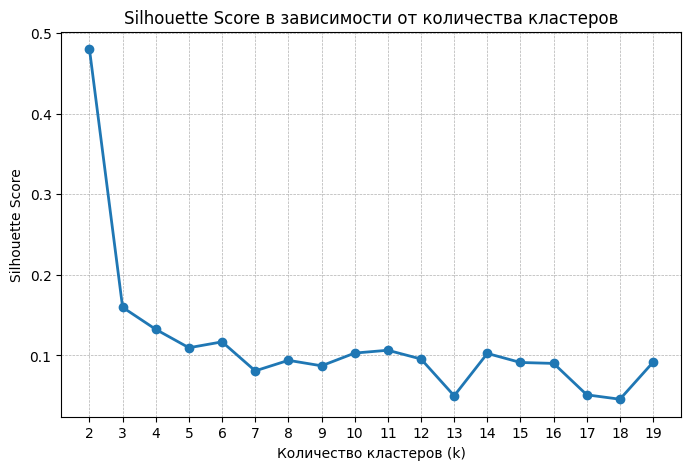

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='o', linewidth=2)
plt.xticks(k_range)
plt.title('Silhouette Score в зависимости от количества кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

### 3 кластера

In [26]:
k_opt = 3

Предобработчик данных, включающий:
- стандартизацию числовых признаков (StandardScaler)
- кодирование категориальных признаков (OneHotEncoder)

In [27]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
])

Pipeline, объединяющий предобработку и алгоритм кластеризации KMeans.

In [28]:
final_pipe = Pipeline([
    ('prep', preprocessor),
    ('kmeans', KMeans(n_clusters=k_opt, random_state=42, n_init=10))
])

In [29]:
df['cluster'] = final_pipe.fit_predict(df)

In [30]:
df['cluster'].value_counts()

cluster
2    460
1    193
0     28
Name: count, dtype: int64

In [31]:
X_prep = final_pipe.named_steps['prep'].transform(df.drop(columns=['cluster']))
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_prep)

In [32]:
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

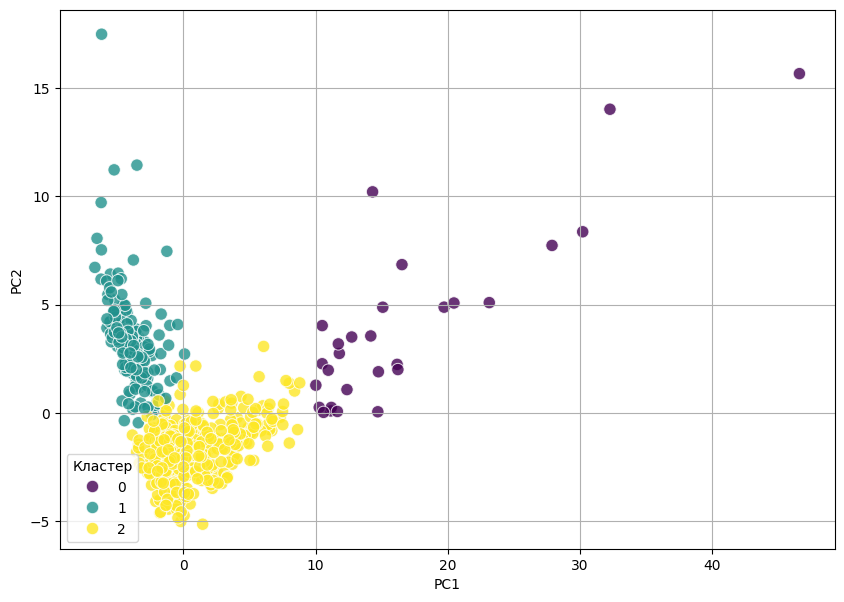

In [33]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='pca1', y='pca2', hue='cluster', palette='viridis', s=80, alpha=0.8)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Кластер')
plt.grid(True)
plt.show()

In [34]:
pca = PCA(n_components=3)
pca_result = pca.fit_transform(df[numeric_features])  
df['pca1_3d'] = pca_result[:, 0]
df['pca2_3d'] = pca_result[:, 1]
df['pca3_3d'] = pca_result[:, 2]

In [35]:
fig = px.scatter_3d(
    df,
    x='pca1_3d',
    y='pca2_3d',
    z='pca3_3d',
    color='cluster',
    opacity=0.7
)

fig.update_layout(
    title='3D визуализация кластеров (интерактивная)',
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    )
)

fig.show()

#### средние значения по кластерам

In [36]:
key_features_extended = [
    # Финансы и инфраструктура 
    'income_total',                    # общий доход
    'income_nonbudget',                # внебюджетные доходы
    'research_services_funds_own_total',  # доходы от научных услуг собств. силами
    'rnd_total_volume',                # общий объём НИОКР
    'rnd_funds_own_total',             # НИОКР собств. силами
    'buildings_area_total',            # общая площадь зданий
    'teaching_lab_buildings_area',     # площадь учебно-лабораторных зданий
    'dorms_area',                      # площадь общежитий
    
    # Студенты
    'students_total',                  # общая численность студентов (бак+спец+маг)
    
    # ЕГЭ
    'ege_min_avg_full_time',           # усреднённый минимальный балл ЕГЭ по направлениям (очн. форма)
    
    # Научная продуктивность (по РИНЦ, на 100 НПР)
    'citations_rinc_5y_per_100_faculty',   # цитирования РИНЦ за 5 лет / 100 НПР
    'publications_rinc_per_100_faculty',   # публикации РИНЦ          / 100 НПР
]

In [37]:
df.groupby('cluster')[key_features_extended].mean().round(2)

,income_total,income_nonbudget,research_services_funds_own_total,rnd_total_volume,rnd_funds_own_total,buildings_area_total,teaching_lab_buildings_area,dorms_area,students_total,ege_min_avg_full_time,citations_rinc_5y_per_100_faculty,publications_rinc_per_100_faculty
cluster,,,,,,,,,,,,
0,12408248.63,5368482.33,2130884.52,2120337.98,2007510.09,470266.36,281748.64,118107.64,20251.68,54.74,2430.00,331.72
1,167031.01,154397.33,8060.04,8936.19,7987.85,7487.21,6254.57,656.56,1193.21,36.72,3936.94,365.62
2,1461651.05,572119.75,120546.15,120457.85,110659.86,92926.79,60749.70,24182.37,6066.31,49.84,1744.70,372.78


#### примеры вузов по кластерам

In [38]:
for cl in sorted(df['cluster'].unique()):
    print(f"КЛАСТЕР {cl} ({len(df[df['cluster']==cl])} вузов)")
    examples = df[df['cluster'] == cl].sample(n=min(5, len(df[df['cluster']==cl])), random_state=42)
    for _, row in examples.iterrows():
        print(f"   • {row['vuz']}  (Регион: {row['region']})")
    
    print("-" * 60)

КЛАСТЕР 0 (28 вузов)
   • федеральное государственное автономное образовательное учреждение высшего образования Первый Московский государственный медицинский университет имени И.М. Сеченова Министерства здравоохранения Российской Федерации (Сеченовский Университет)  (Регион: г.Москва)
   • Федеральное государственное автономное образовательное учреждение высшего образования «Национальный исследовательский Томский государственный университет»  (Регион: Томская область)
   • федеральное государственное автономное образовательное учреждение высшего образования «Российский университет транспорта»  (Регион: г.Москва)
   • Федеральное государственное автономное образовательное учреждение высшего образования "Южный федеральный университет"  (Регион: Ростовская область)
   • Автономная некоммерческая образовательная организация высшего образования «Сколковский институт науки и технологий»  (Регион: г.Москва)
------------------------------------------------------------
КЛАСТЕР 1 (193 вузов)
   

### 7 кластеров

In [39]:
k_opt = 7

In [40]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
])

In [41]:
final_pipe = Pipeline([
    ('prep', preprocessor),
    ('kmeans', KMeans(n_clusters=k_opt, random_state=42, n_init=10))
])

In [42]:
df['cluster'] = final_pipe.fit_predict(df)

In [43]:
df['cluster'].value_counts()

cluster
4    277
5    174
0    131
1     68
2     26
3      4
6      1
Name: count, dtype: int64

In [44]:
X_prep = final_pipe.named_steps['prep'].transform(df.drop(columns=['cluster']))
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_prep)

In [45]:
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]

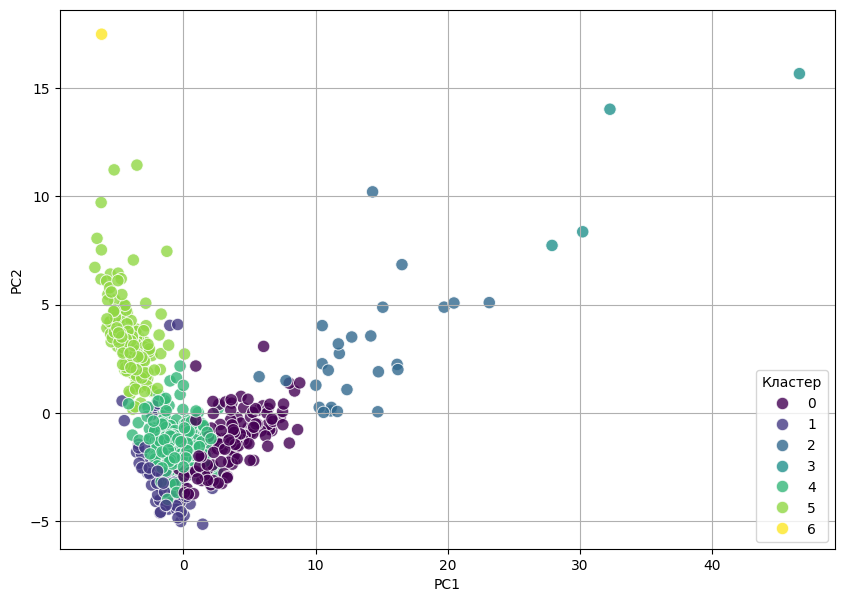

In [46]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='pca1', y='pca2', hue='cluster', palette='viridis', s=80, alpha=0.8)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Кластер')
plt.grid(True)
plt.show()

In [47]:
pca = PCA(n_components=3)
pca_result = pca.fit_transform(df[numeric_features]) 
df['pca1_3d'] = pca_result[:, 0]
df['pca2_3d'] = pca_result[:, 1]
df['pca3_3d'] = pca_result[:, 2]

In [48]:
fig = px.scatter_3d(
    df,
    x='pca1_3d',
    y='pca2_3d',
    z='pca3_3d',
    color='cluster',
    opacity=0.7
)

fig.update_layout(
    title='3D визуализация кластеров',
    scene=dict(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3'
    )
)

fig.show()

#### средние значения по кластерам

In [50]:
df.groupby('cluster')[key_features_extended].mean().round(2)

,income_total,income_nonbudget,research_services_funds_own_total,rnd_total_volume,rnd_funds_own_total,buildings_area_total,teaching_lab_buildings_area,dorms_area,students_total,ege_min_avg_full_time,citations_rinc_5y_per_100_faculty,publications_rinc_per_100_faculty
cluster,,,,,,,,,,,,
0,3019242.86,1328331.03,282668.92,286393.83,266039.17,162895.57,106951.68,40778.95,10693.63,48.95,1713.03,346.53
1,480865.54,153408.08,27666.81,28860.57,22134.78,21182.25,14305.01,5636.72,915.04,58.58,1809.36,158.39
2,9792597.88,4167749.85,1788954.85,1724775.90,1618704.08,369208.92,214428.04,98693.04,17484.54,53.88,2356.82,326.90
3,25351031.55,11472846.32,4163465.45,4198548.62,4088007.05,963766.75,625870.25,200747.50,31622.50,60.24,2416.04,308.35
4,878213.53,292387.83,48427.28,51020.19,45831.08,71979.99,46710.64,19432.16,4855.49,47.30,2033.48,436.19
5,140934.42,135606.95,6759.65,7192.40,6686.35,6810.00,5970.58,463.02,1141.89,36.83,3717.79,370.51
6,8348.80,8243.00,3386.00,2210.00,2210.00,1204.00,1204.00,0.00,4.00,0.00,1875.86,137.93


#### примеры вузов по кластерам

In [62]:
for cl in sorted(df['cluster'].unique()):
    print(f"КЛАСТЕР {cl} ({len(df[df['cluster']==cl])} вузов)")
    examples = df[df['cluster'] == cl].sample(n=min(5, len(df[df['cluster']==cl])), random_state=42)
    for _, row in examples.iterrows():
        print(f"   • {row['vuz']}  (Регион: {row['region']})")
    
    print("-" * 60)

КЛАСТЕР 0 (131 вузов)
   • федеральное государственное бюджетное образовательное учреждение высшего образования "Ижевская государственная медицинская академия" Министерства здравоохранения Российской Федерации  (Регион: Удмуртская Республика)
   • федеральное государственное бюджетное образовательное учреждение высшего образования "Северо-Западный государственный медицинский университет имени И.И. Мечникова" Министерства здравоохранения Российской Федерации  (Регион: г.Санкт-Петербург)
   • федеральное государственное бюджетное образовательное учреждение высшего образования «Владимирский государственный университет имени Александра Григорьевича и Николая Григорьевича Столетовых»  (Регион: Владимирская область)
   • федеральное государственное бюджетное образовательное учреждение высшего образования «Смоленский государственный медицинский университет» Министерства здравоохранения Российской Федерации  (Регион: Смоленская область)
   • федеральное государственное бюджетное образовательно

In [52]:
cluster_means = df.groupby('cluster')[numeric_features].mean()
between_cluster_variance = cluster_means.var(axis=0)

In [53]:
top_variance = between_cluster_variance.sort_values(ascending=False)
top_variance.head(15)

income_total                         8.731308e+13
income_nonbudget                     1.780749e+13
rnd_total_volume                     2.503329e+12
research_services_funds_own_total    2.484903e+12
rnd_funds_own_total                  2.362860e+12
buildings_area_total                 1.221681e+11
edu_income_foreign_sources           8.579456e+10
edu_funds_from_foreign_entities      8.579456e+10
teaching_lab_buildings_area          5.070876e+10
dorms_area                           5.500302e+09
research_units_area                  2.907418e+08
rnd_funds_from_foreign_entities      1.841907e+08
rnd_income_foreign_sources           1.841907e+08
students_total                       1.349801e+08
students_full_time                   1.191236e+08
dtype: float64

#### топ 8 признаков с наибольшей межкластерной дисперсией

In [54]:
key_features = [
    'income_total',                          # общий доход 
    'income_nonbudget',                      # внебюджетные доходы
    'research_services_funds_own_total',     # доходы от научных услуг собств. силами
    'rnd_total_volume',                      # общий объём НИОКР
    'rnd_funds_own_total',                   # НИОКР собств силами
    'buildings_area_total',                  # общая площадь зданий
    'teaching_lab_buildings_area',           # площадь учебно-лабораторных зданий
    'dorms_area',                             # площадь общежитий
    'students_total'
]

In [55]:
cluster_means = df.groupby('cluster')[key_features].mean().round(2)

Стандартизируем признаки, чтобы сравнивать между собой

In [56]:
cluster_means_std = (cluster_means - cluster_means.mean()) / cluster_means.std()

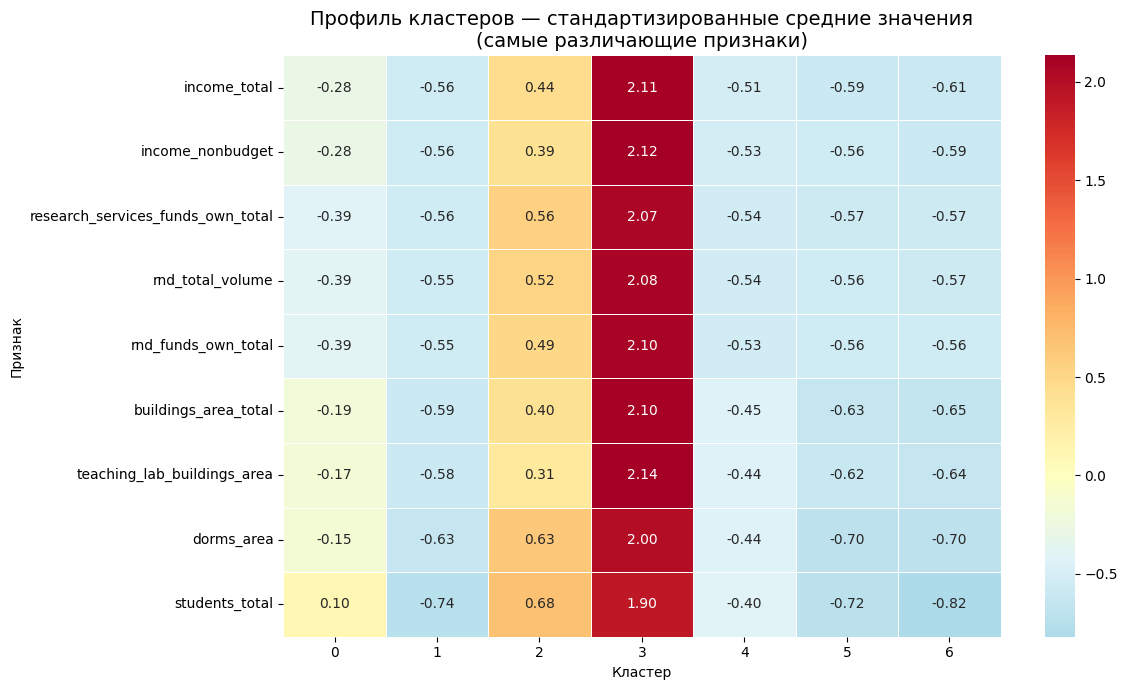

In [57]:
plt.figure(figsize=(12, 7))
sns.heatmap(
    cluster_means_std.T, 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlBu_r', 
    center=0, 
    linewidths=0.5
)
plt.title('Профиль кластеров — стандартизированные средние значения\n(самые различающие признаки)', fontsize=14)
plt.ylabel('Признак')
plt.xlabel('Кластер')
plt.tight_layout()
plt.show()

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_3002/62422613.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_3002/62422613.py:8: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_3002/62422613.py:12: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_3002/62422613.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variab

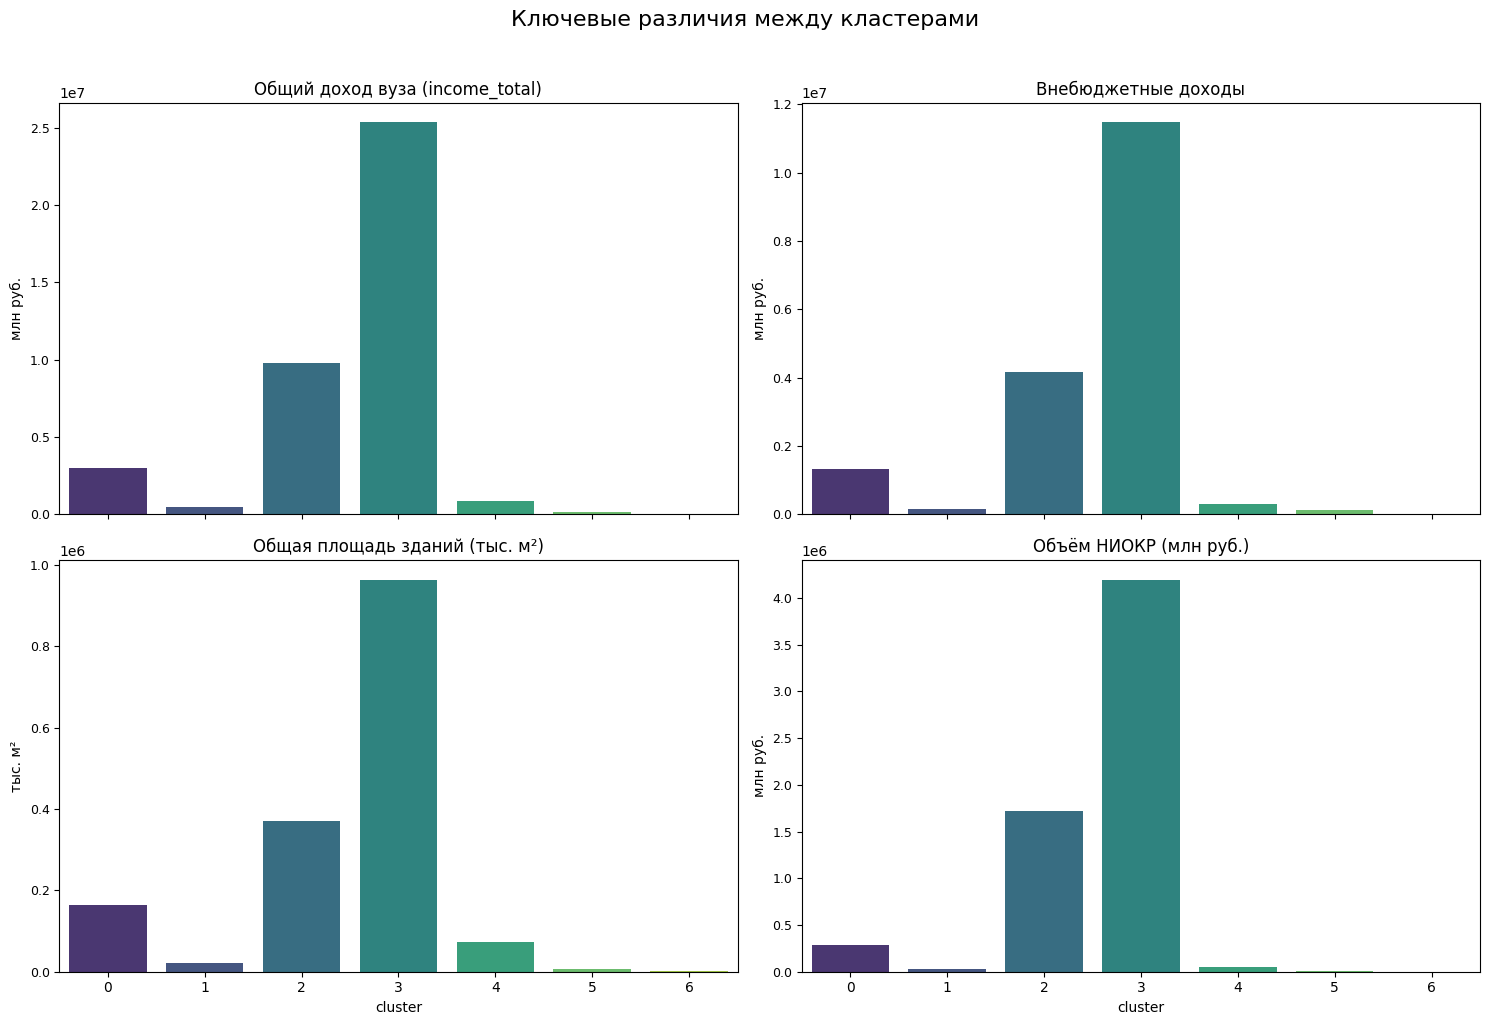

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)


sns.barplot(data=df, x='cluster', y='income_total', ax=axes[0,0], palette='viridis', errorbar=None)
axes[0,0].set_title('Общий доход вуза (income_total)', fontsize=12)
axes[0,0].set_ylabel('млн руб.')

sns.barplot(data=df, x='cluster', y='income_nonbudget', ax=axes[0,1], palette='viridis', errorbar=None)
axes[0,1].set_title('Внебюджетные доходы', fontsize=12)
axes[0,1].set_ylabel('млн руб.')

sns.barplot(data=df, x='cluster', y='buildings_area_total', ax=axes[1,0], palette='viridis', errorbar=None)
axes[1,0].set_title('Общая площадь зданий (тыс. м²)', fontsize=12)
axes[1,0].set_ylabel('тыс. м²')

sns.barplot(data=df, x='cluster', y='rnd_total_volume', ax=axes[1,1], palette='viridis', errorbar=None)
axes[1,1].set_title('Объём НИОКР (млн руб.)', fontsize=12)
axes[1,1].set_ylabel('млн руб.')

for ax in axes.flat:
    ax.tick_params(axis='x', labelsize=10)
    ax.tick_params(axis='y', labelsize=9)

plt.suptitle('Ключевые различия между кластерами', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()